## Initialization

#### Import Library, find available devices

In [15]:
# Initialization code for 3.3 V SiGe LVR Load Regulation Testing.
# This block identifies and initializes the connected SMUs (Source Measure Units).
# If running for the first time, ensure the SMU names are correctly referenced in the subsequent code block.

# This program sweeps VIN for a fixed VREF and measures total quiescent current (IQ) and VOUT. 
# This program sets up a directory for all measurements taken at a specific temperature by prompting the user for the temperature.
# This program creates a .csv file to save the measurements for a VREF in the temperature directory. 

# The setup assumes the use of two SMUs:
# - One dedicated to VIN sweeps.
# - One Sinks a load current and measures VOUT.

import pyvisa                    # Importing the pyvisa library for instrument communication
import time                      # Importing the time module to handle time-related tasks (e.g., delays)
import matplotlib.pyplot as plt  # Importing matplotlib.pyplot for plotting graphs and visualizing data
import numpy as np               # Importing numpy for numerical operations, particularly with arrays
import pandas as pd              # Importing pandas as pd for data manipulation and analysis
import os                        # Importing os to interact with the operating system, such as handling file paths
import csv                       # Importing csv to read from and write to CSV files
from IPython.display import display, clear_output
from datetime import date           # Importing date to read current date
from collections import defaultdict
from scipy.optimize import curve_fit

In [ ]:
# Loads ICASL.py from a higher directory
# This file contains functions written by us that can be called with "ICASL.example_function_name"
import importlib.util    # Used to load python files more dynamically (ICASL.py)
quiet=True
current_dir = "."
target_file = "ICASL.py"
target_name = "ICASL"
while True:
    if not quiet: print(current_dir)
    # Check if ICASL is in the current directory
    ICASL_path = os.path.join(current_dir, target_file)
    if not quiet: print(ICASL_path)
    if os.path.isfile(ICASL_path):
        # Loads ICASL.py
        spec = importlib.util.spec_from_file_location(target_name, ICASL_path)
        ICASL = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(ICASL)
        break
    else:
        # Move one level up
        parent_dir = os.path.join(current_dir, "..")
        if not quiet: print(parent_dir)
        if current_dir == parent_dir:  # Reached the root directory
            raise ValueError("ICASL.py not found")
        else:
            current_dir = parent_dir
ICASL.test()

## Data

#### Store/Load Data

In [10]:
def store_data(df, save_dir, SOC, test_name):
    df.to_csv(os.path.join(save_dir, f'{test_name}__SOC={SOC}.csv'), index=False)
def update_lines():
    #ax1.plot(times[-1], VBAT[-1],marker='.', color='blue')
    #ax2.plot(times[-1], IBAT[-1],marker='.', color='red')
    lineV.set_data(times, VBAT)
    ax1.relim()
    ax1.autoscale_view()
    lineI.set_data(times, IBAT)
    ax2.relim()
    ax2.autoscale_view()
    lineDOD.set_data(times, DOD)
    ax3.relim()
    ax3.autoscale_view()
    display(fig)
    clear_output(wait = True)
# def load_data(load_dir, SOC, test_name):
#     df = ICASL.read_csv(os.path.join(load_dir, f"{test_name}__SOC={VSET}.csv"))
#     df = ICASL.fix_dataframe(df)
#     return df

#### Full Procedure

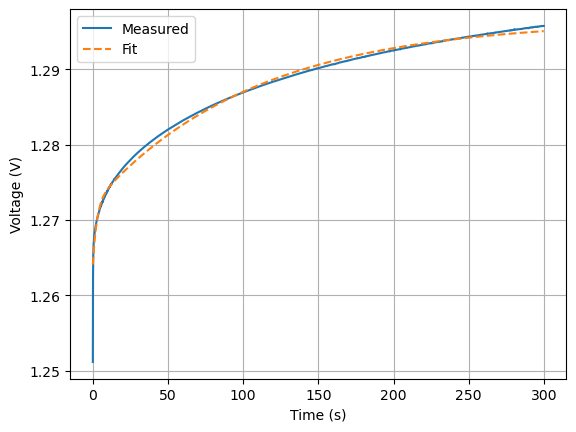

In [24]:
df = pd.read_csv("Test_1\SOC=1.2000326821555691.csv")
times1 = df["times"]
VBAT1 = df["voltage"]
IBAT1 = df["current"]
DOD1 = df["DOD"]
VBAT= VBAT1.values.tolist()[:1602]
IBAT= IBAT1[:1602]
DOD= DOD1[:1602]
times= times1[:1602]
times = times - times[0]
#Setup Plot
#fig = plt.figure()
# fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(10, 10))
# ax1.set_ylabel('VBAT(V)')
# ax3.set_xlabel('time(s)')
# ax2.set_ylabel('IBAT(A)')
# ax3.set_ylabel('DOD(mAh)')
# lineV, = ax1.plot([], [], '.-', color='blue')
# lineV.set_data(times, VBAT)
# lineI, = ax2.plot([], [], '.-', color='red')
# lineI.set_data(times, IBAT)
# lineDOD, = ax3.plot([], [], '.-', color='green')
# lineDOD.set_data(times, DOD)
# update_lines()

### Curve Fitting ###

def double_exp(t, A, B1, tau1, B2, tau2):
    return A + B1*np.exp(-t/tau1) + B2*np.exp(-t/tau2)


A0 = VBAT[-1]                  # final voltage
B1_0 = VBAT[0] - VBAT[-1]        # initial drop
B2_0 = 0.1 * B1_0

tau1_0 = 1
tau2_0 = 50

p0 = [A0, B1_0, tau1_0, B2_0, tau2_0]



popt, pcov = curve_fit(double_exp, times, VBAT, p0=p0, maxfev=10000)

A, B1, tau1, B2, tau2 = popt


I = 1.0

R1 = -B1 / I
R2 = -B2 / I

# time constants
# tau = R * C → C = tau / R

C1 = tau1 / R1
C2 = tau2 / R2


v_fit = double_exp(times, *popt)

plt.plot(times, VBAT, label="Measured")
plt.plot(times, v_fit, '--', label="Fit")
plt.xlabel("Time (s)")
plt.ylabel("Voltage (V)")
plt.legend()
plt.grid()
plt.show()




